In [1]:
import numpy as np
import matplotlib.pyplot as plt

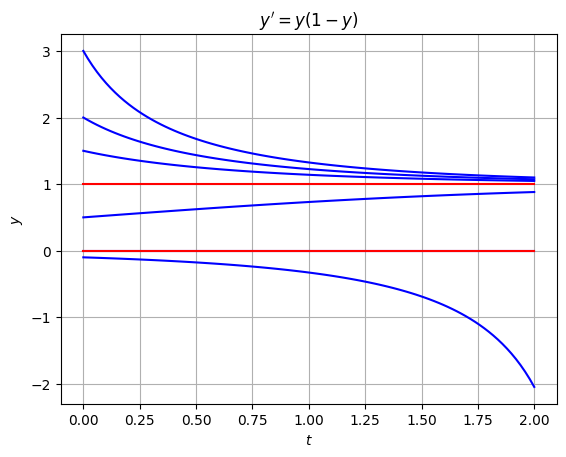

In [2]:
t = np.linspace(0,2,100)
for y0 in [-0.1,0.0,0.5,1.5,2,3]:
    C = y0/(1 - y0)
    y = C*np.exp(t)/(1 + C*np.exp(t))
    plt.plot(t,y,'b')
plt.plot(t,1+0*t,'r')   # solução constante y(t) = 1
plt.plot(t,0*t,'r')     # solução constante y(t) = 0
plt.title(r"$y' = y(1-y)$"), plt.grid(True)
plt.xlabel("$t$"), plt.ylabel("$y$")
plt.show()

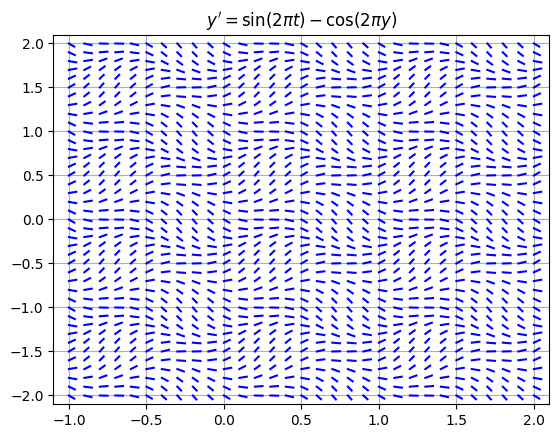

In [3]:
f = lambda t,y: np.sin(2*np.pi*t) - np.cos(2*np.pi*y)
h = 0.1; L = 0.5*h;
t_grid = np.arange(-1,2+h,h)
y_grid = np.arange(-2,2+h,h)
for t in t_grid:
    for y in y_grid:
       m = f(t,y)
       theta = np.arctan(m)
       plt.plot([t,t + L*np.cos(theta)],
                [y,y + L*np.sin(theta)],'b')

plt.title(r"$y' = \sin(2 \pi t) - \cos(2 \pi y)$")
plt.grid(True), plt.xlim([-1-h,2+h]), plt.ylim([-2-h,2+h])
plt.show()

In [4]:
def odeEuler(f,t,y0):
    """Método de Euler para y' = f(t,y), y(t[0]) = y0.
    Funciona para equações escalares (y0 número) e para sistemas (y0 lista/array)."""
    y0 = np.asarray(y0, dtype=float)
    y = np.zeros((len(t),) + y0.shape)
    y[0] = y0
    for n in range(0,len(t)-1):
        h = t[n+1] - t[n]
        k1 = np.asarray(f(t[n],y[n]))
        y[n+1] = y[n] + k1*h
    return y

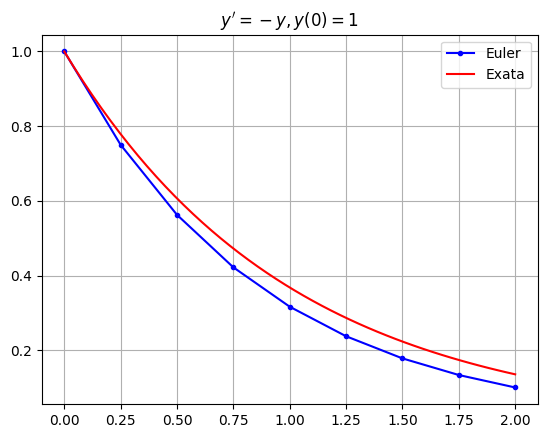

In [5]:
f = lambda t,y: -y
t0 = 0; tf = 2; h = 0.25; N = int((tf - t0)/h);
t = np.linspace(t0,tf,N+1); y0 = 1;
y = odeEuler(f,t,y0)
plt.plot(t,y,'b.-'), plt.grid(True)
t_exact = np.linspace(t0,tf,50)
y_exact = np.exp(-t_exact)
plt.plot(t_exact,y_exact,'r')
plt.title("$y'=-y,y(0)=1$"), plt.legend(["Euler","Exata"])
plt.show()

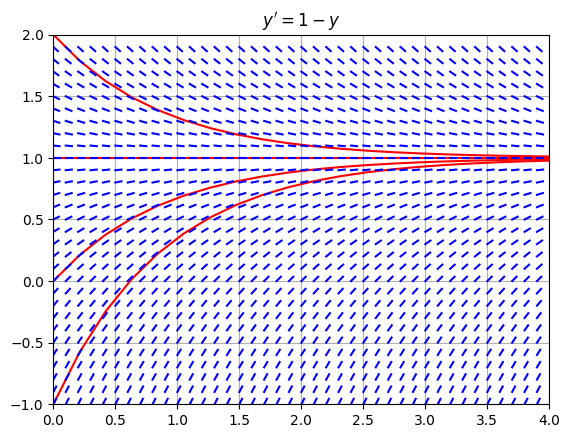

In [6]:
f = lambda t,y: 1 - y
h = 0.1; L = 0.5*h;

t = np.linspace(0,4,20)
for y0 in range(-1,3):
    y = odeEuler(f,t,y0)
    plt.plot(t,y,'r-')

t_grid = np.arange(0,4,h)
y_grid = np.arange(-1,2,h)
for t in t_grid:
    for y in y_grid:
        m = f(t,y)
        theta = np.arctan(m)
        plt.plot([t,t + L*np.cos(theta)],
                 [y,y + L*np.sin(theta)],'b')


plt.grid(True), plt.xlim([0,4]), plt.ylim([-1,2])
plt.title("$y' = 1 - y$")
plt.show()

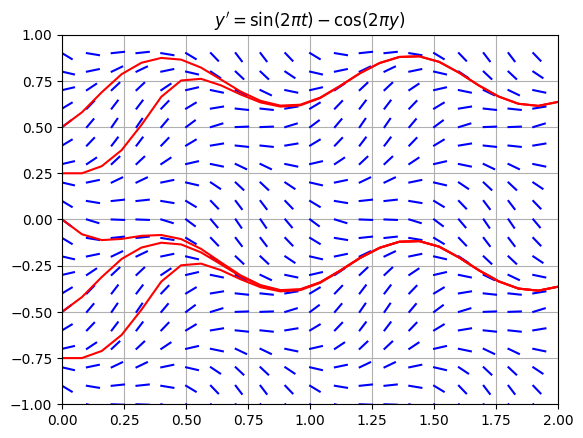

In [7]:
f = lambda t,y: np.sin(2*np.pi*t) - np.cos(2*np.pi*y)
h = 0.1; L = 0.5*h;
t_grid = np.arange(0,2,h)
y_grid = np.arange(-1,1,h)
for t in t_grid:
    for y in y_grid:
        m = f(t,y)
        theta = np.arctan(m)
        plt.plot([t,t + L*np.cos(theta)],
                 [y,y + L*np.sin(theta)],'b')

t = np.linspace(0,2,26)
for y0 in [-0.75,-0.5,0.0,0.25,0.5]:
    y = odeEuler(f,t,y0)
    plt.plot(t,y,'r-')

plt.grid(True), plt.xlim([0,2]), plt.ylim([-1,1])
plt.title(r"$y' = \sin(2 \pi t) - \cos(2 \pi y)$")
plt.show()